In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv(r"D:\HVIA\task2\Sharnouby_Enterprise\Sales_Transactions.csv")
df.head()

,Row_ID,Invoice_ID,Order_Date,Month_Key,Location_ID,Location_Name,Channel,Customer_ID,Customer_Type,Customer_Governorate,...,Estimated_COGS_EGP,Gross_Profit_EGP,Gross_Margin_Pct,Payment_Method,Returned,Return_Date,Return_Reason,Refund_Value_EGP,Quality_Related_Return,Data_Class
0,0,INV0000001,2024-05-11,2024-05,LOC002,LEO MODA Online Store,Online,C18976,Retail,Cairo,...,247.57,82.23,0.2493,Wallet,No,NaN,No return,0.0,No,Modeled training transaction anchored to publi...
1,1,INV0000002,2025-07-31,2025-07,LOC001,LEO MODA - Sidi Bishr Store,Retail,C22543,Retail,Alexandria,...,163.31,67.89,0.2936,Card,No,NaN,No return,0.0,No,Modeled training transaction anchored to publi...
2,2,INV0000003,2026-05-23,2026-05,LOC003,El-Sharnouby Wholesale Desk,Wholesale,C13351,Wholesale,Alexandria,...,4301.71,512.69,0.1065,Cash,No,NaN,No return,0.0,No,Modeled training transaction anchored to publi...
3,3,INV0000004,2024-06-05,2024-06,LOC003,El-Sharnouby Wholesale Desk,Wholesale,C21377,Wholesale,Dakahlia,...,10451.13,907.59,0.0799,Bank Transfer,No,NaN,No return,0.0,No,Modeled training transaction anchored to publi...
4,4,INV0000005,2025-12-28,2025-12,LOC001,LEO MODA - Sidi Bishr Store,Retail,C21499,Retail,Alexandria,...,186.16,53.04,0.2217,Cash,No,NaN,No return,0.0,No,Modeled training transaction anchored to publi...


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180000 entries, 0 to 179999
Data columns (total 30 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Row_ID                  180000 non-null  int64  
 1   Invoice_ID              180000 non-null  object 
 2   Order_Date              180000 non-null  object 
 3   Month_Key               180000 non-null  object 
 4   Location_ID             180000 non-null  object 
 5   Location_Name           180000 non-null  object 
 6   Channel                 180000 non-null  object 
 7   Customer_ID             180000 non-null  object 
 8   Customer_Type           180000 non-null  object 
 9   Customer_Governorate    180000 non-null  object 
 10  Product_ID              180000 non-null  object 
 11  SKU                     180000 non-null  object 
 12  Product_Name            180000 non-null  object 
 13  Product_Family          180000 non-null  object 
 14  Size                

In [4]:
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"], errors="coerce"
)

df["Invoice_ID"] = df["Invoice_ID"].astype("string").str.strip()
df["Customer_ID"] = df["Customer_ID"].astype("string").str.strip()

df["Customer_Type"] = (
    df["Customer_Type"].astype("string").str.strip().str.lower()
)


In [5]:
customers_df = df[
    df["Customer_Type"].notna()
    & df["Customer_Type"].ne("wholesale")
].copy()


In [6]:
customers_df = customers_df.dropna(
    subset=["Customer_ID", "Invoice_ID", "Order_Date"]
)

customers_df = customers_df[
    customers_df["Customer_ID"].ne("")
    & customers_df["Invoice_ID"].ne("")
]

In [7]:
observation_date = customers_df["Order_Date"].max().normalize()

In [8]:
last_purchase = customers_df.groupby("Customer_ID")[
    "Order_Date"
].max()

recency = (
    observation_date - last_purchase.dt.normalize()
).dt.days.rename("Recency")

In [9]:
frequency = customers_df.groupby("Customer_ID")[
    "Invoice_ID"
].nunique().rename("Frequency")

In [10]:
monetary = customers_df.groupby("Customer_ID")[
    "Net_Sales_EGP"
].sum(min_count=1).rename("Monetary")

In [11]:
invoice_sales = (
    customers_df.groupby(["Customer_ID", "Invoice_ID"])[
        "Net_Sales_EGP"
    ]
    .sum(min_count=1)
    .rename("Invoice_Value")
    .reset_index()
)

In [12]:
average_order_value = (
    invoice_sales.groupby("Customer_ID")["Invoice_Value"]
    .mean()
    .rename("Average_Order_Value")
)

In [13]:
invoice_dates = (
    customers_df[["Customer_ID", "Invoice_ID", "Order_Date"]]
    .dropna(subset=["Customer_ID", "Invoice_ID", "Order_Date"])
    .groupby(["Customer_ID", "Invoice_ID"], as_index=False)
    .agg(Order_Date=("Order_Date", "min"))
    .sort_values(["Customer_ID", "Order_Date"])
)

# Calculate days between consecutive purchases
invoice_dates["Days_Between_Purchases"] = (
    invoice_dates.groupby("Customer_ID")["Order_Date"]
    .diff()
    .dt.total_seconds()
    .div(86400)
)

# Calculate purchase regularity
purchase_regularity = (
    invoice_dates.groupby("Customer_ID")["Days_Between_Purchases"]
    .mean()
    .fillna(0)
    .rename("Purchase_Regularity")
)

In [14]:
customer_features = pd.concat(
    [
        recency,
        frequency,
        monetary,
        average_order_value,
        purchase_regularity,
    ],
    axis=1,
).reset_index()

customer_features.head()

,Customer_ID,Recency,Frequency,Monetary,Average_Order_Value,Purchase_Regularity
0,C00001,24,6,2324.80,387.466667,22.600000
1,C00002,26,7,2767.25,395.321429,116.166667
2,C00003,13,4,1355.75,338.937500,98.333333
3,C00005,211,2,515.25,257.625000,123.000000
4,C00006,108,2,857.50,428.750000,56.000000


In [15]:
customer_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24035 entries, 0 to 24034
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Customer_ID          24035 non-null  string 
 1   Recency              24035 non-null  int64  
 2   Frequency            24035 non-null  int64  
 3   Monetary             24035 non-null  float64
 4   Average_Order_Value  24035 non-null  float64
 5   Purchase_Regularity  24035 non-null  float64
dtypes: float64(3), int64(2), string(1)
memory usage: 1.1 MB


In [16]:
customer_features.describe()

,Recency,Frequency,Monetary,Average_Order_Value,Purchase_Regularity
count,24035.000000,24035.000000,24035.000000,24035.000000,24035.000000
mean,142.526274,5.619014,3218.965920,495.564366,88.307812
std,130.207990,4.835723,5102.848122,244.766217,74.418460
min,0.000000,1.000000,216.750000,216.750000,0.000000
25%,48.000000,2.000000,897.000000,357.361458,43.585714
50%,103.000000,4.000000,1929.850000,443.500000,79.833333
75%,194.000000,8.000000,3589.825000,547.641429,119.000000
max,959.000000,41.000000,108607.230000,5232.098571,865.000000


In [17]:

features = [
    "Recency",
    "Frequency",
    "Monetary",
    "Average_Order_Value",
    "Purchase_Regularity"
]

X = customer_features[features].copy()



# 3. Invalid values
print("\nNon-positive or negative values:")
print((X < 0).sum())

# 4. Skewness
print("\nSkewness:")
print(X.skew().sort_values(ascending=False))

# 5. Detailed distribution
print("\nDistribution:")
print(X.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T)


Non-positive or negative values:
Recency                0
Frequency              0
Monetary               0
Average_Order_Value    0
Purchase_Regularity    0
dtype: int64

Skewness:
Monetary               5.922874
Average_Order_Value    4.036137
Purchase_Regularity    1.885231
Frequency              1.801918
Recency                1.552086
dtype: float64

Distribution:
                       count         mean          std     min      1%     5%  \
Recency              24035.0   142.526274   130.207990    0.00    1.00    9.0   
Frequency            24035.0     5.619014     4.835723    1.00    1.00    1.0   
Monetary             24035.0  3218.965920  5102.848122  216.75  254.15  299.0   
Average_Order_Value  24035.0   495.564366   244.766217  216.75  250.75  283.3   
Purchase_Regularity  24035.0    88.307812    74.418460    0.00    0.00    0.0   

                            25%          50%          75%       95%  \
Recency               48.000000   103.000000   194.000000   421.000  

In [18]:
features = [
    "Recency",
    "Frequency",
    "Monetary",
    "Average_Order_Value",
    "Purchase_Regularity"
]

X = customer_features[features].copy()

# Apply log1p transformation
X_log = np.log1p(X)

# Compare skewness before and after transformation
skew_comparison = pd.DataFrame({
    "Original_Skewness": X.skew(),
    "Log1p_Skewness": X_log.skew()
})

skew_comparison["Skewness_Improvement"] = (
    skew_comparison["Original_Skewness"].abs()
    - skew_comparison["Log1p_Skewness"].abs()
)

skew_comparison.sort_values(
    "Original_Skewness",
    ascending=False
)

,Original_Skewness,Log1p_Skewness,Skewness_Improvement
Monetary,5.922874,0.151424,5.771450
Average_Order_Value,4.036137,1.156157,2.879980
Purchase_Regularity,1.885231,-1.406394,0.478837
Frequency,1.801918,0.214936,1.586982
Recency,1.552086,-0.956071,0.596015


In [19]:

print("Original feature correlations:")
display(X.corr().round(2))

print("Correlations after log1p:")
display(X_log.corr().round(2))

Original feature correlations:


,Recency,Frequency,Monetary,Average_Order_Value,Purchase_Regularity
Recency,1.00,-0.02,0.02,0.06,-0.14
Frequency,-0.02,1.00,0.79,0.37,-0.04
Monetary,0.02,0.79,1.00,0.72,-0.07
Average_Order_Value,0.06,0.37,0.72,1.00,-0.04
Purchase_Regularity,-0.14,-0.04,-0.07,-0.04,1.00


Correlations after log1p:


,Recency,Frequency,Monetary,Average_Order_Value,Purchase_Regularity
Recency,1.00,-0.03,-0.01,0.03,-0.06
Frequency,-0.03,1.00,0.94,0.32,0.56
Monetary,-0.01,0.94,1.00,0.61,0.56
Average_Order_Value,0.03,0.32,0.61,1.00,0.12
Purchase_Regularity,-0.06,0.56,0.56,0.12,1.00


In [20]:
customer_features["Has_Multiple_Invoices"] = (
    customer_features["Frequency"] > 1
).astype(int)

print(
    customer_features[
        ["Frequency", "Has_Multiple_Invoices"]
    ][customer_features["Has_Multiple_Invoices"] == 0].head()
)

    Frequency  Has_Multiple_Invoices
5           1                      0
8           1                      0
10          1                      0
16          1                      0
17          1                      0


In [21]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

# Features
features = [
    "Recency",
    "Frequency",
    "Monetary",
    "Average_Order_Value",
    "Purchase_Regularity",
    "Has_Multiple_Invoices"
]

X = customer_features[features].copy()

# Apply log1p to reduce positive skewness
log_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "Average_Order_Value",
    "Purchase_Regularity"
]

X[log_features] = np.log1p(X[log_features])

# Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled shape:", X_scaled.shape)


Scaled shape: (24035, 6)


In [22]:
results = []

for k in range(1, 15):
    gmm = GaussianMixture(
        n_components=k,
        covariance_type="full",
        n_init=5,
        random_state=42,
        reg_covar=1e-6
    )

    gmm.fit(X_scaled)

    results.append({
        "n_clusters": k,
        "BIC": gmm.bic(X_scaled),
        "AIC": gmm.aic(X_scaled)
    })

results_df = pd.DataFrame(results)

print(results_df.sort_values("BIC"))

    n_clusters            BIC            AIC
13          14 -613042.970014 -616205.091169
12          13 -600825.285500 -603760.963196
11          12 -572951.280183 -575660.514421
9           10 -553636.194426 -555892.541746
10          11 -551868.095592 -554350.886370
8            9 -544921.536757 -546951.440619
7            8 -496344.651780 -498148.112183
6            7 -488937.914554 -490514.931499
5            6 -487217.090432 -488567.663918
4            5 -442076.146504 -443200.276531
3            4 -415361.690911 -416259.377480
2            3 -354690.443776 -355361.686886
1            2 -288576.108467 -289020.908117
0            1  172936.553272  172718.197080


In [23]:
best_k = int(
    results_df.loc[results_df["BIC"].idxmin(), "n_clusters"]
)

print("Best number of clusters according to BIC:", best_k)

Best number of clusters according to BIC: 14


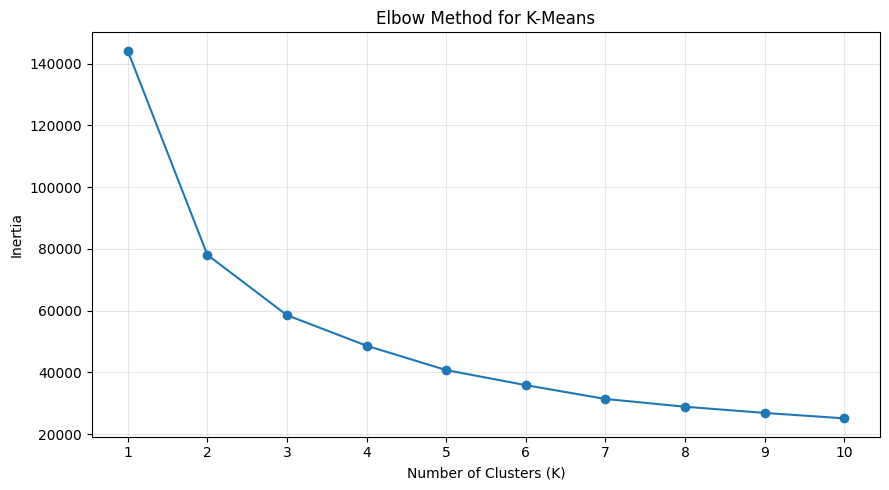

In [24]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

inertias = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(k_values, inertias, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
kmeans = KMeans(
    n_clusters=4,
    init="k-means++",
    n_init=10,
    random_state=42
)

cluster_labels = kmeans.fit_predict(X_scaled)

customer_features = customer_features.copy()
customer_features["Cluster"] = cluster_labels

customer_features.head()

,Customer_ID,Recency,Frequency,Monetary,Average_Order_Value,Purchase_Regularity,Has_Multiple_Invoices,Cluster
0,C00001,24,6,2324.80,387.466667,22.600000,1,3
1,C00002,26,7,2767.25,395.321429,116.166667,1,3
2,C00003,13,4,1355.75,338.937500,98.333333,1,3
3,C00005,211,2,515.25,257.625000,123.000000,1,2
4,C00006,108,2,857.50,428.750000,56.000000,1,2


In [32]:
import joblib

joblib.dump(kmeans, "kmeans_model.pkl")

['kmeans_model.pkl']

In [26]:

cluster_summary = customer_features.groupby("Cluster").agg(
    Customer_Count=("Recency", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Avg_Order_Value=("Average_Order_Value", "mean"),
    Avg_Purchase_Regularity=("Purchase_Regularity", "mean")
).round(2)

cluster_summary["Customer_Percentage"] = (
    cluster_summary["Customer_Count"]
    / len(customer_features) * 100
).round(2)

cluster_summary.sort_values(
    "Avg_Monetary", ascending=False
)


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_Order_Value,Avg_Purchase_Regularity,Customer_Percentage
Cluster,,,,,,,
0,6304,168.46,11.24,7786.30,641.26,77.85,26.23
3,4551,25.19,5.93,2744.17,469.87,117.71,18.93
2,9214,180.29,3.61,1521.58,429.37,118.95,38.34
1,3966,148.20,1.00,447.41,447.26,0.00,16.50


In [27]:

cluster_profiles = customer_features.groupby("Cluster").agg(
    Customers=("Recency", "size"),
    Recency_Median=("Recency", "median"),
    Frequency_Median=("Frequency", "median"),
    Monetary_Median=("Monetary", "median"),
    AOV_Median=("Average_Order_Value", "median"),
    Regularity_Median=("Purchase_Regularity", "median")
).round(2)

cluster_profiles


,Customers,Recency_Median,Frequency_Median,Monetary_Median,AOV_Median,Regularity_Median
Cluster,,,,,,
0,6304,130.0,10.0,4900.52,520.87,73.61
1,3966,109.0,1.0,348.00,348.00,0.00
2,9214,139.0,3.0,1432.82,406.50,103.50
3,4551,23.0,5.0,2463.15,446.01,104.80


In [28]:
segment_names = {
    0: "High-Value, Frequent Customers",
    1: "One-Time, Low-Spending Customers",
    2: "Occasional, Moderate-Spending Customers",
    3: "Recently Active Customers"
}

customer_features = customer_features.copy()

customer_features["Cluster"] = kmeans.predict(X_scaled)
customer_features["Segment"] = customer_features["Cluster"].map(segment_names)

if (
    "Customer_ID" not in customer_features.columns
    and customer_features.index.name == "Customer_ID"
):
    customer_features = customer_features.reset_index()

customer_features.to_csv(
    "Customer_Segmentation.csv",
    index=False
)

customer_features.head()

,Customer_ID,Recency,Frequency,Monetary,Average_Order_Value,Purchase_Regularity,Has_Multiple_Invoices,Cluster,Segment
0,C00001,24,6,2324.80,387.466667,22.600000,1,3,Recently Active Customers
1,C00002,26,7,2767.25,395.321429,116.166667,1,3,Recently Active Customers
2,C00003,13,4,1355.75,338.937500,98.333333,1,3,Recently Active Customers
3,C00005,211,2,515.25,257.625000,123.000000,1,2,"Occasional, Moderate-Spending Customers"
4,C00006,108,2,857.50,428.750000,56.000000,1,2,"Occasional, Moderate-Spending Customers"


In [29]:

from scipy.stats import percentileofscore

metrics = [
    "Recency",
    "Frequency",
    "Monetary",
    "Average_Order_Value",
    "Purchase_Regularity"
]

cluster_summary = customer_features.groupby(
    ["Cluster", "Segment"]
).agg(
    Customers=("Recency", "size"),
    **{
        f"{metric}_Median": (metric, "median")
        for metric in metrics
    }
).reset_index()

cluster_summary["Customer_Percentage"] = (
    cluster_summary["Customers"]
    / len(customer_features) * 100
).round(2)

for metric in metrics:
    cluster_summary[f"{metric}_Percentile"] = (
        cluster_summary[f"{metric}_Median"].apply(
            lambda value: percentileofscore(
                customer_features[metric].dropna(),
                value,
                kind="rank"
            )
        )
    ).round(2)

cluster_summary.to_csv(
    "Customer_Segmentation_Summary.csv",
    index=False
)

cluster_summary


,Cluster,Segment,Customers,Recency_Median,Frequency_Median,Monetary_Median,Average_Order_Value_Median,Purchase_Regularity_Median,Customer_Percentage,Recency_Percentile,Frequency_Percentile,Monetary_Percentile,Average_Order_Value_Percentile,Purchase_Regularity_Percentile
0,0,"High-Value, Frequent Customers",6304,130.0,10.0,4900.525,520.869722,73.6125,26.23,59.28,84.89,85.45,69.93,45.08
1,1,"One-Time, Low-Spending Customers",3966,109.0,1.0,348.000,348.000000,0.0000,16.50,52.36,8.25,8.29,21.92,8.27
2,2,"Occasional, Moderate-Spending Customers",9214,139.0,3.0,1432.825,406.500000,103.5000,38.34,62.01,36.59,38.96,39.15,67.03
3,3,Recently Active Customers,4551,23.0,5.0,2463.150,446.010000,104.8000,18.93,11.67,57.21,59.97,50.91,67.80


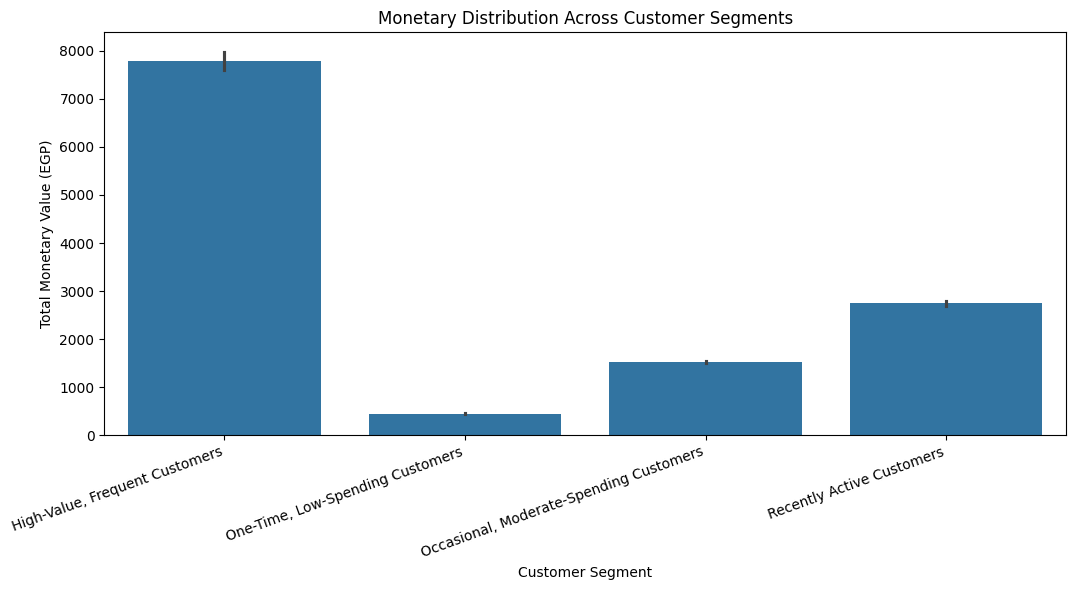

In [31]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 6))

sns.barplot(
    data=customer_features,
    x="Segment",
    y="Monetary",
    order=[segment_names[i] for i in range(4)]
)

plt.xlabel("Customer Segment")
plt.ylabel("Total Monetary Value (EGP)")
plt.title("Monetary Distribution Across Customer Segments")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()
